# Session 2 — Linear regression and optimization

**Question:** How does a prediction rule acquire its coefficients?

Read each explanation before running its cell. Run from a fresh Python 3 kernel, top to bottom. No downloads or GPU are needed. Seeds are fixed. Companion: [lecture PDF](../PdfLectures/02_linear_regression_and_optimization.pdf). Try the [student application](../StudentApplications/02_linear_regression_and_optimization_student.ipynb) afterward.

## Problem statement

A service team wants to estimate how many milliseconds a new request will take, before it runs. This time the required output is a numerical duration, not a slow/not-slow label. Investigate whether payload size and the number of waiting jobs help predict that duration.

**Given.** The notebook generates 600 fictional past requests, each with payload in MB, queue length, and measured duration in ms. It includes random variation, so even a useful model will make errors. Supplied partitions contain 360 training, 120 validation, and 120 test rows. The generator and split are already written; no dataset collection is required.

**Concrete example.** For an arriving request carrying 4 MB with 3 jobs waiting, the model should return one number in ms. The simulator has a mean duration of 40 + 8*4 + 3*3 = 81 ms for these inputs; a particular observed duration may differ because of noise. The exercise is to estimate a rule from past observations, not to copy the simulator coefficients into a predictor.

**Objective.** Fit a rule for request duration and understand where its coefficients come from.

**Route and expected result.** Compare the mean baseline, a payload-only line, and a two-input model. Check the formula and gradient calculations, choose a fitted candidate by validation RMSE (prediction error in ms), and inspect its final test error. Explain slopes and why noise prevents perfect predictions.

**Your role in this worked notebook.** The code is complete. Read the predictions and questions, run the supplied cells in order, interpret their tables and figures, and attempt the closing exercise before reading its answer notes. The separate student application contains the implementation tasks.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, log_loss, mean_squared_error, mean_absolute_error)
print('Python', sys.version.split()[0], '| scikit-learn', sklearn.__version__)
plt.rcParams.update({'figure.figsize': (6, 4), 'axes.grid': True, 'grid.alpha': 0.2})

Python 3.12.9 | scikit-learn 1.8.0


## 1. A simpler numerical target
Use a separate simulator to make parameter fitting transparent:
$$y=40+8s+3q+\epsilon,\quad \epsilon\sim N(0,8^2).$$
Payload $s$ is in MB, queue $q$ is a count, and latency $y$ is in ms. The known generating
coefficients are a teaching aid, not estimates. This example has no missing features.
The 60/20/20 split uses seed 23. Compare a training-mean baseline, payload alone, and both
features. Select between the fitted candidates by validation RMSE before opening test data.

In [2]:
rng = np.random.default_rng(31)
n = 600
X = pd.DataFrame({'payload': rng.uniform(0.5, 10, n), 'queue': rng.poisson(3, n)})
y = 40 + 8*X.payload + 3*X.queue + rng.normal(0, 8, n)
train_valid, test = train_test_split(np.arange(n), test_size=0.2, random_state=23)
train, valid = train_test_split(train_valid, test_size=0.25, random_state=23)
assert not (set(train) & set(valid) or set(train) & set(test) or set(valid) & set(test))
Xtr, Xva, Xte = X.iloc[train], X.iloc[valid], X.iloc[test]
ytr, yva, yte = y.iloc[train], y.iloc[valid], y.iloc[test]
def regression_scores(y_true, prediction):
    return {'MAE_ms': mean_absolute_error(y_true, prediction),
            'RMSE_ms': np.sqrt(mean_squared_error(y_true, prediction))}
print('Rows:', len(train), len(valid), len(test))

Rows: 360 120 120


## 2. Fit one line from a formula
For $\hat y=b+ws$, least squares gives
$$w=\frac{\sum(s_i-\bar s)(y_i-\bar y)}{\sum(s_i-\bar s)^2},\quad b=\bar y-w\bar s.$$
Each residual is observed minus predicted. The slope is ms/MB; it represents a fitted
association, not a controlled causal effect. **Predict first:** why will this one-feature
intercept generally differ from the generating intercept 40?

Fitted line: 47.985 + 8.134 * payload


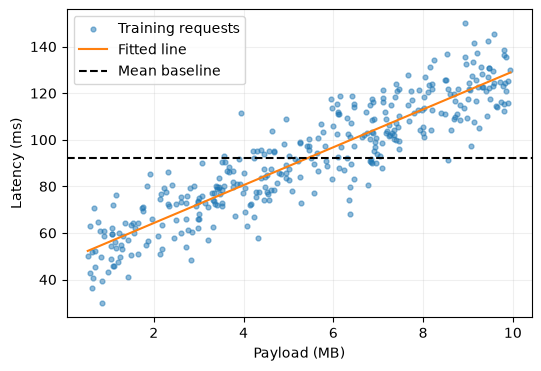

In [3]:
s = Xtr.payload.to_numpy(); target = ytr.to_numpy()
w = np.sum((s-s.mean())*(target-target.mean()))/np.sum((s-s.mean())**2)
b = target.mean() - w*s.mean()
one = LinearRegression().fit(Xtr[['payload']], ytr)
np.testing.assert_allclose([b, w], [one.intercept_, one.coef_[0]])
print(f'Fitted line: {b:.3f} + {w:.3f} * payload')
plt.scatter(s, target, s=12, alpha=0.5, label='Training requests')
grid = np.linspace(s.min(), s.max(), 100)
plt.plot(grid, b+w*grid, color='tab:orange', label='Fitted line')
plt.axhline(target.mean(), color='black', linestyle='--', label='Mean baseline')
plt.xlabel('Payload (MB)'); plt.ylabel('Latency (ms)'); plt.legend(); plt.show()

## 3. Multiple regression as array operations
Include a column of ones for the intercept: $D_i=(1,s_i,q_i)$.
Then $\hat y=D\beta$, where $\beta=(b,w_s,w_q)^T$. Avoid explicitly inverting $D^TD$;
`lstsq` is a numerical solver for the same least-squares problem.

With $J=\|D\beta-y\|^2/(2n)$, the gradient is $D^T(D\beta-y)/n$.
The next cell checks that our derivative matches small numerical perturbations.

In [4]:
scale = StandardScaler().fit(Xtr)
D = np.column_stack([np.ones(len(Xtr)), scale.transform(Xtr)])
beta_exact = np.linalg.lstsq(D, target, rcond=None)[0]
def objective(beta): return np.mean((D @ beta - target)**2)/2
def gradient(beta): return D.T @ (D @ beta - target)/len(target)
probe = np.array([1., 2., 3.]); eps = 1e-5
finite_difference = np.array([(objective(probe+eps*e)-objective(probe-eps*e))/(2*eps)
                              for e in np.eye(3)])
np.testing.assert_allclose(gradient(probe), finite_difference, rtol=1e-6)
print('Analytic gradient matches finite differences.')

Analytic gradient matches finite differences.


## 4. Watch gradient descent learn
Update $\beta\leftarrow\beta-\eta\nabla J$. Use 0.1 after scaling, stop when the gradient
norm is below $10^{-7}$, and cap at 5,000 iterations. Report convergence rather than assuming
that an iteration budget means success. Compare the final predictions to the direct solver.
A smaller training objective is optimization progress; generalization needs held-out rows.

Converged: True | Updates: 197
Original-unit coefficients: [38.43346577  8.04932099  3.30200597]


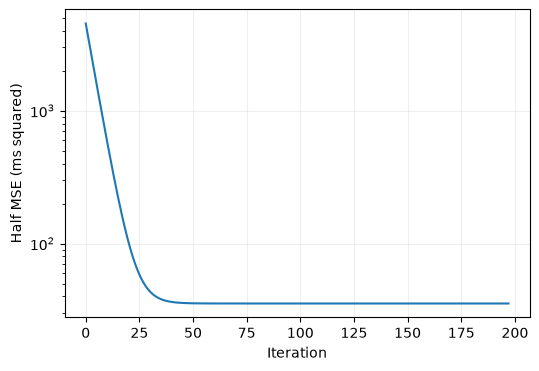

Loss with step 3.0: first/last 4529.03050058163 1412942966433.7437


In [5]:
beta = np.zeros(3); history = []
for step in range(5000):
    history.append(objective(beta))
    g = gradient(beta)
    if np.linalg.norm(g) < 1e-7: break
    beta -= 0.1*g
converged = np.linalg.norm(gradient(beta)) < 1e-7
assert converged
np.testing.assert_allclose(D @ beta, D @ beta_exact, atol=1e-5)
slopes = beta[1:]/scale.scale_
intercept = beta[0] - slopes @ scale.mean_
print('Converged:', converged, '| Updates:', step)
print('Original-unit coefficients:', np.r_[intercept, slopes])
plt.plot(history); plt.yscale('log'); plt.xlabel('Iteration'); plt.ylabel('Half MSE (ms squared)'); plt.show()
# A deliberately excessive step shows why step size matters.
bad = np.zeros(3); bad_history = []
for _ in range(15):
    bad_history.append(objective(bad)); bad -= 3.0*gradient(bad)
print('Loss with step 3.0: first/last', bad_history[0], bad_history[-1])

## 5. Select the relationship and inspect residuals
The candidate family and selection metric are fixed in advance. Validation selects the input
columns; test then evaluates the frozen choice. A residual plot on training rows helps detect
omitted structure. A good-looking residual plot does not prove that a model will generalize.

,MAE_ms,RMSE_ms
payload only,7.247033,9.496264
payload + queue,5.630832,7.418472


Frozen choice: payload + queue


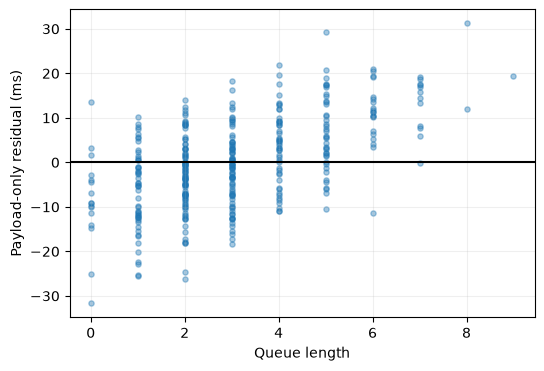

In [6]:
candidates = {'payload only': ['payload'], 'payload + queue': ['payload', 'queue']}
models = {name: LinearRegression().fit(Xtr[cols], ytr) for name, cols in candidates.items()}
validation = pd.DataFrame({name: regression_scores(yva, model.predict(Xva[candidates[name]]))
                           for name, model in models.items()}).T
winner = validation.RMSE_ms.idxmin()
display(validation); print('Frozen choice:', winner)
residual = ytr - one.predict(Xtr[['payload']])
plt.scatter(Xtr.queue, residual, alpha=0.4, s=14)
plt.axhline(0, color='black'); plt.xlabel('Queue length'); plt.ylabel('Payload-only residual (ms)'); plt.show()

In [7]:
baseline = DummyRegressor(strategy='mean').fit(Xtr, ytr)
final = models[winner].predict(Xte[candidates[winner]])
display(pd.DataFrame([regression_scores(yte, baseline.predict(Xte)), regression_scores(yte, final)],
                     index=['training-mean baseline', winner]))

,MAE_ms,RMSE_ms
training-mean baseline,19.798896,23.214939
payload + queue,6.872242,8.635232


## Closing exercise
For $x=(0,1,2)$ and $y=(1,2,2)$, calculate the fitted line and its residuals. Starting
from zero, take one gradient step of size 0.1 on half MSE. Why is that first step not the
least-squares solution? Then implement a different learning rate in the student application.

**Answer notes:** The line is $7/6+x/2$; residuals are $(-1/6,1/3,-1/6)$.
At zero, the gradient for $(b,w)$ is $(-5/3,-2)$ and the first iterate is $(1/6,0.2)$.
The one-feature intercept also absorbs the average queue contribution. Reducing training
loss alone cannot select the better representation for unseen requests.